In [3]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [4]:
GROUP = "C4"
DTYPE="HRLK"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C4_10,25,"[DATA/TRAINING/C4/C4_10/IMG_6597.HEIC, DATA/TR..."
1,C4_11,27,"[DATA/TRAINING/C4/C4_11/IMG_6727.HEIC, DATA/TR..."
2,C4_12,27,"[DATA/TRAINING/C4/C4_12/IMG_6857.HEIC, DATA/TR..."
3,C4_13,30,"[DATA/TRAINING/C4/C4_13/IMG_6998.HEIC, DATA/TR..."
4,C4_14,27,"[DATA/TRAINING/C4/C4_14/IMG_7250.HEIC, DATA/TR..."
5,C4_15,25,"[DATA/TRAINING/C4/C4_15/IMG_7388.HEIC, DATA/TR..."
6,C4_16,28,"[DATA/TRAINING/C4/C4_16/IMG_7517.HEIC, DATA/TR..."


In [5]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [6]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [7]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_6597.HEIC')

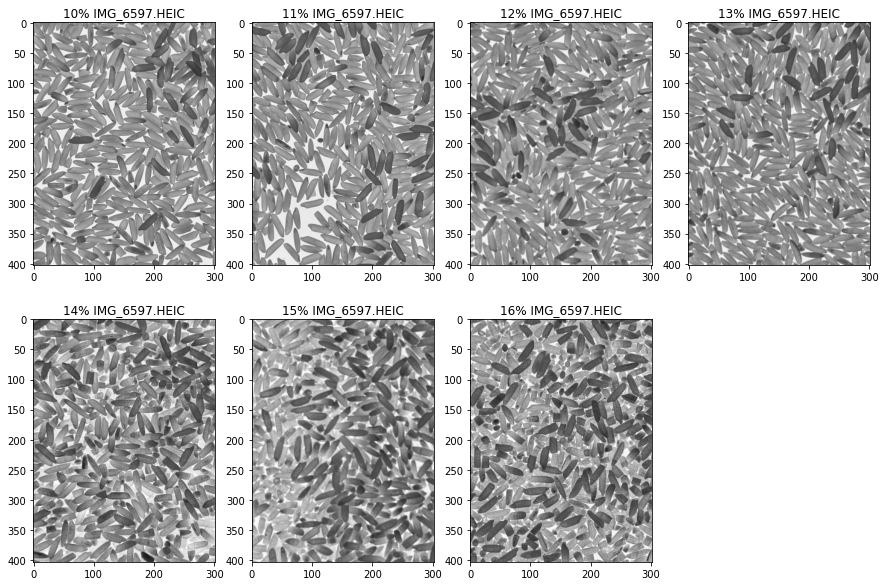

In [8]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][0].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[0][0].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[0][0].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[0][0].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[0][0].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[0][0].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[0][0].split("/")[4])

In [154]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [155]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.000626,269.373392,0.921624,1718.475886,0.240110,296.062362,6604.530151,7.917781,11.832273,0.000351,...,0.000279,4.553637,-0.247174,0.983641,25,1008,756,3,IMG_6597.HEIC,10
1,0.000609,252.920214,0.931723,1852.170183,0.248941,296.960969,7155.760518,7.972784,11.836689,0.000365,...,0.000272,4.623850,-0.245463,0.983682,25,1008,756,3,IMG_6598.HEIC,10
2,0.000485,257.743070,0.936205,2020.077448,0.244244,306.985136,7822.566722,8.203667,12.147255,0.000358,...,0.000270,4.610246,-0.261741,0.988528,25,1008,756,3,IMG_6599.HEIC,10
3,0.000649,243.392433,0.934463,1856.917988,0.248054,300.057170,7184.279520,7.925774,11.761771,0.000367,...,0.000275,4.576646,-0.246474,0.983532,25,1008,756,3,IMG_6600.HEIC,10
4,0.000706,289.023393,0.923710,1894.237311,0.248148,294.616371,7287.925851,7.880857,11.750927,0.000360,...,0.000294,4.505103,-0.252956,0.984575,25,1008,756,3,IMG_6601.HEIC,10
5,0.000713,265.882885,0.932835,1979.325774,0.254322,305.991195,7651.420209,7.881686,11.692835,0.000374,...,0.000288,4.535882,-0.249957,0.983929,25,1008,756,3,IMG_6602.HEIC,10
6,0.000706,274.847576,0.933419,2064.012032,0.261635,305.118626,7981.200551,7.922222,11.718493,0.000386,...,0.000306,4.463677,-0.262011,0.986701,25,1008,756,3,IMG_6603.HEIC,10
7,0.000862,282.723117,0.930038,2020.548860,0.254087,307.719674,7799.472323,7.690399,11.465858,0.000378,...,0.000305,4.465769,-0.244013,0.980868,25,1008,756,3,IMG_6604.HEIC,10
8,0.000734,288.458475,0.921889,1846.454534,0.239318,310.973189,7097.359659,7.757368,11.655986,0.000348,...,0.000272,4.615029,-0.228955,0.977262,25,1008,756,3,IMG_6605.HEIC,10
9,0.000723,283.890224,0.930019,2028.344260,0.241509,313.129457,7829.486815,7.772733,11.642934,0.000357,...,0.000270,4.636249,-0.228854,0.977401,25,1008,756,3,IMG_6606.HEIC,10


# Classification

In [156]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [157]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [158]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [159]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [160]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [161]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.736842,0.738095,0.761905,0.749811,HRLK,C4,RF_C,25,1008,756,3
1,2,0.789474,0.859524,0.761905,0.807776,HRLK,C4,RF_C,25,1008,756,3
2,3,0.736842,0.776190,0.738095,0.756664,HRLK,C4,RF_C,25,1008,756,3
3,4,0.789474,0.892857,0.761905,0.822199,HRLK,C4,RF_C,25,1008,756,3
4,5,0.894737,0.916667,0.904762,0.910675,HRLK,C4,RF_C,25,1008,756,3
5,6,0.789474,0.833333,0.809524,0.821256,HRLK,C4,RF_C,25,1008,756,3
6,7,0.684211,0.690476,0.690476,0.690476,HRLK,C4,RF_C,25,1008,756,3
7,8,0.684211,0.702381,0.666667,0.684058,HRLK,C4,RF_C,25,1008,756,3
8,9,0.578947,0.595238,0.547619,0.570437,HRLK,C4,RF_C,25,1008,756,3
9,10,0.833333,0.869048,0.809524,0.838230,HRLK,C4,RF_C,25,1008,756,3


In [162]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C4,RF_C,0.751754,0.745238,0.765158,0.787381


### MLP Classifier

In [163]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [164]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [165]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.736842,0.800000,0.761905,0.780488,HRLK,C4,MLP_C,25,1008,756,3
1,2,0.842105,0.845238,0.833333,0.839243,HRLK,C4,MLP_C,25,1008,756,3
2,3,0.842105,0.785714,0.809524,0.797441,HRLK,C4,MLP_C,25,1008,756,3
3,4,0.736842,0.773810,0.714286,0.742857,HRLK,C4,MLP_C,25,1008,756,3
4,5,0.842105,0.833333,0.833333,0.833333,HRLK,C4,MLP_C,25,1008,756,3
5,6,0.842105,0.892857,0.809524,0.849151,HRLK,C4,MLP_C,25,1008,756,3
6,7,0.789474,0.845238,0.785714,0.814390,HRLK,C4,MLP_C,25,1008,756,3
7,8,0.736842,0.761905,0.761905,0.761905,HRLK,C4,MLP_C,25,1008,756,3
8,9,0.736842,0.819048,0.738095,0.776467,HRLK,C4,MLP_C,25,1008,756,3
9,10,0.611111,0.688095,0.619048,0.651748,HRLK,C4,MLP_C,25,1008,756,3


In [166]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C4,MLP_C,0.771637,0.766667,0.784702,0.804524


### XGBoost Classifier

In [167]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [168]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.833333,0.809524,0.821256,HRLK,C4,XGB_C,25,1008,756,3
1,2,0.736842,0.788095,0.738095,0.762276,HRLK,C4,XGB_C,25,1008,756,3
2,3,0.736842,0.761905,0.738095,0.749811,HRLK,C4,XGB_C,25,1008,756,3
3,4,0.736842,0.728571,0.714286,0.721358,HRLK,C4,XGB_C,25,1008,756,3
4,5,0.736842,0.809524,0.738095,0.772161,HRLK,C4,XGB_C,25,1008,756,3
5,6,0.842105,0.880952,0.857143,0.868885,HRLK,C4,XGB_C,25,1008,756,3
6,7,0.631579,0.680952,0.595238,0.635217,HRLK,C4,XGB_C,25,1008,756,3
7,8,0.736842,0.678571,0.761905,0.717828,HRLK,C4,XGB_C,25,1008,756,3
8,9,0.526316,0.685714,0.571429,0.623377,HRLK,C4,XGB_C,25,1008,756,3
9,10,0.722222,0.761905,0.714286,0.737327,HRLK,C4,XGB_C,25,1008,756,3


In [169]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C4,XGB_C,0.719591,0.72381,0.74095,0.760952


# External validation

In [170]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C4_10,5,"[DATA/TEST/C4/C4_10/IMG_6593.HEIC, DATA/TEST/C..."
1,C4_11,5,"[DATA/TEST/C4/C4_11/IMG_6718.HEIC, DATA/TEST/C..."
2,C4_12,5,"[DATA/TEST/C4/C4_12/IMG_6846.HEIC, DATA/TEST/C..."
3,C4_13,5,"[DATA/TEST/C4/C4_13/IMG_6983.HEIC, DATA/TEST/C..."
4,C4_14,5,"[DATA/TEST/C4/C4_14/IMG_7240.HEIC, DATA/TEST/C..."
5,C4_15,5,"[DATA/TEST/C4/C4_15/IMG_7378.HEIC, DATA/TEST/C..."
6,C4_16,5,"[DATA/TEST/C4/C4_16/IMG_7507.HEIC, DATA/TEST/C..."


In [171]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [172]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [173]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.000479,256.801844,0.936389,2018.525147,0.247677,291.832412,7817.298745,8.180060,12.105903,0.000359,...,0.000300,4.455111,-0.281302,0.991227,25,1008,756,3,IMG_6593.HEIC,10
1,0.000490,265.372092,0.930864,1919.204436,0.237134,293.267349,7411.445653,8.102170,12.072817,0.000340,...,0.000283,4.524552,-0.267044,0.988778,25,1008,756,3,IMG_6594.HEIC,10
2,0.000528,268.337553,0.928946,1888.259283,0.240962,298.344338,7284.699579,8.046546,11.978314,0.000345,...,0.000290,4.492777,-0.266728,0.988355,25,1008,756,3,IMG_6595.HEIC,10
3,0.000534,275.671203,0.932873,2053.363977,0.238322,303.133948,7937.784707,8.031526,11.967694,0.000351,...,0.000289,4.515459,-0.261168,0.987323,25,1008,756,3,IMG_6596.HEIC,10
4,0.000723,283.890224,0.930019,2028.344260,0.241509,313.129457,7829.486815,7.772733,11.642934,0.000357,...,0.000270,4.636249,-0.228854,0.977401,25,1008,756,3,IMG_660.HEIC,10
0,0.000414,218.759445,0.943342,1930.526155,0.234325,288.201635,7503.345173,8.219922,12.166035,0.000343,...,0.000253,4.645121,-0.255423,0.987489,25,1008,756,3,IMG_6718.HEIC,11
1,0.000387,233.479985,0.939205,1920.209670,0.224557,287.030485,7447.358694,8.227454,12.241676,0.000324,...,0.000244,4.690747,-0.250626,0.986633,25,1008,756,3,IMG_6720.HEIC,11
2,0.000548,295.884574,0.917141,1785.474072,0.228694,299.297490,6846.011715,7.959395,11.960615,0.000329,...,0.000250,4.709629,-0.229337,0.979370,25,1008,756,3,IMG_6723.HEIC,11
3,0.000515,280.475940,0.919640,1745.128082,0.223970,300.053081,6700.036388,8.015175,12.037998,0.000318,...,0.000253,4.654099,-0.241227,0.982994,25,1008,756,3,IMG_6725.HEIC,11
4,0.000538,278.764932,0.919575,1733.076305,0.228616,295.248760,6653.540289,7.995588,11.990326,0.000327,...,0.000259,4.630298,-0.242554,0.983150,25,1008,756,3,IMG_6726.HEIC,11


In [174]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [175]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [176]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [177]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [178]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       1.00      1.00      1.00         5
     Class 3       1.00      0.60      0.75         5
     Class 4       0.57      0.80      0.67         5
     Class 5       0.60      0.60      0.60         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.83        35
   macro avg       0.85      0.83      0.83        35
weighted avg       0.85      0.83      0.83        35



## MLP

In [179]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [180]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      0.60      0.75         5
     Class 2       0.71      1.00      0.83         5
     Class 3       0.75      0.60      0.67         5
     Class 4       0.50      0.60      0.55         5
     Class 5       0.75      0.60      0.67         5
     Class 6       0.67      0.80      0.73         5

    accuracy                           0.74        35
   macro avg       0.77      0.74      0.74        35
weighted avg       0.77      0.74      0.74        35



## XGBC

In [181]:
y_pred = modelXGBC.predict(X_test_scale) 

In [182]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      0.60      0.75         5
     Class 2       0.83      1.00      0.91         5
     Class 3       0.50      0.60      0.55         5
     Class 4       0.75      0.60      0.67         5
     Class 5       0.40      0.40      0.40         5
     Class 6       0.50      0.60      0.55         5

    accuracy                           0.69        35
   macro avg       0.71      0.69      0.69        35
weighted avg       0.71      0.69      0.69        35

